# 10 — Phase 2 model evaluation

**Research question:** CNN đã chọn có sai số và giới hạn nào theo nhóm và biến dạng ảnh?

Baseline: metadata Ridge, silhouette+metadata Ridge; model chính: CNN hai view. Checkpoint giữ nguyên. Protocol: split theo người; testA/testB riêng; mỗi người trọng số ngang nhau.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
for path in [ROOT, ROOT / "scripts"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
from IPython.display import display, Markdown
import numpy as np
import matplotlib.pyplot as plt


In [2]:
report = json.loads((ROOT / "experiments/bodym_phase2/metrics.json").read_text(encoding="utf-8"))
import hashlib
assert hashlib.sha256((ROOT / report["config"]["checkpoint"]).read_bytes()).hexdigest() == report["checkpoint_sha256"]
print("Checkpoint unchanged:", not report["checkpoint_changed"])
print("Subgroup bins:", report["subgroup_bins"])
print("Packages/device:", report["versions"], report["device"])
display(Markdown((ROOT / "experiments/bodym_phase2/report.md").read_text(encoding="utf-8").replace("![Subgroups and robustness](evaluation.png)", "")))

Checkpoint unchanged: True
Subgroup bins: {'fit_subjects': 1614, 'bmi_quartile_edges': [22.323755264282227, 24.71784210205078, 27.624836444854736], 'height_weight_min': [141.0, 28.700000762939453], 'height_weight_max': [197.1999969482422, 181.89999389648438]}
Packages/device: {'torch': '2.11.0+cu128', 'numpy': '2.4.6', 'Pillow': '12.3.0'} cuda


# Phase 2 — Body Image Intelligence

Checkpoint CNN giữ nguyên; không train hoặc chọn lại mô hình theo test.

## Dataset & integrity

Đã kiểm tra 17,956 ảnh silhouette và 9 CSV bằng source ETag/size.
Nhãn số đo từ 3D scan/mesh; không phải phiếu InBody hay nhãn mỡ/cơ. Train/test tách người; testA/testB chung 1 ID.

## MAE/RMSE — mỗi người trọng số bằng nhau

| Model | Split | Chest MAE | Waist MAE | Hip MAE | Mean MAE | Chest RMSE | Waist RMSE | Hip RMSE |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| selected_cnn | testA | 2.342 | 2.270 | 1.519 | 2.043 | 2.986 | 2.831 | 1.965 |
| metadata_ridge | testA | 2.903 | 3.306 | 2.018 | 2.742 | 3.743 | 3.911 | 2.535 |
| silhouette_metadata_ridge | testA | 2.284 | 2.613 | 1.840 | 2.246 | 2.936 | 3.405 | 2.358 |
| selected_cnn | testB | 2.797 | 2.944 | 2.186 | 2.642 | 3.792 | 3.801 | 2.866 |
| metadata_ridge | testB | 3.277 | 3.561 | 2.446 | 3.095 | 4.272 | 4.570 | 3.269 |
| silhouette_metadata_ridge | testB | 2.952 | 3.719 | 2.399 | 3.023 | 4.069 | 5.014 | 3.250 |

## Quality audit

| Split/view | Images | Requires review | Unusable | Flags |
|---|---:|---:|---:|---|
| train/mask | 6134 | 123 | 0 | {'fragmented_foreground': 17, 'foreground_touches_frame': 112} |
| train/mask_left | 6134 | 1691 | 0 | {'foreground_touches_frame': 1584, 'fragmented_foreground': 149} |
| testA/mask | 1684 | 34 | 0 | {'foreground_touches_frame': 33, 'fragmented_foreground': 2} |
| testA/mask_left | 1684 | 596 | 0 | {'foreground_touches_frame': 596, 'fragmented_foreground': 1} |
| testB/mask | 1160 | 55 | 0 | {'foreground_touches_frame': 50, 'fragmented_foreground': 7} |
| testB/mask_left | 1160 | 545 | 0 | {'foreground_touches_frame': 535, 'fragmented_foreground': 25} |

Không loại ảnh bị gắn cờ khỏi đánh giá đầy đủ. Chạm mép/fragmentation chỉ là chỉ dấu kỹ thuật, không chứng minh ảnh thiếu cơ thể hay sai tư thế.

## Subgroup errors (CNN)

BMI quartiles lấy từ 1.614 người FIT; là nhóm mô tả, không phải phân loại sức khỏe.

| Split | Group | Subjects | Mean MAE (cm) | Small group (<20) |
|---|---|---:|---:|---|
| testA | provided_gender_female | 41 | 2.078 | False |
| testA | provided_gender_male | 46 | 2.012 | False |
| testA | fit_bmi_Q1 | 30 | 1.981 | False |
| testA | fit_bmi_Q2 | 29 | 1.925 | False |
| testA | fit_bmi_Q3 | 14 | 2.113 | True |
| testA | fit_bmi_Q4 | 14 | 2.353 | True |
| testA | outside_fit_height_weight_range | 1 | 2.594 | True |
| testB | provided_gender_female | 243 | 2.633 | False |
| testB | provided_gender_male | 157 | 2.657 | False |
| testB | fit_bmi_Q1 | 141 | 2.266 | False |
| testB | fit_bmi_Q2 | 79 | 2.283 | False |
| testB | fit_bmi_Q3 | 80 | 2.579 | False |
| testB | fit_bmi_Q4 | 100 | 3.508 | False |
| testB | outside_fit_height_weight_range | 0 | N/A | True |

## Synthetic robustness (subset)

Biến dạng mask gốc trước preprocessing; một cặp/người, tối đa 128 người/tập.
Không tương đương đánh giá ánh sáng, camera, pose RGB hoặc thiếu trang phục phù hợp.

| Split | Transform | Retained/attempted | Mean MAE (cm) | Delta vs clean subset (cm) |
|---|---|---:|---:|---:|
| testA | identity | 87/87 | 2.049 | +0.000 |
| testA | translate | 87/87 | 2.049 | +0.000 |
| testA | erode_2px | 87/87 | 2.041 | -0.008 |
| testA | dilate_2px | 87/87 | 2.019 | -0.030 |
| testA | rotate_5deg | 87/87 | 2.348 | +0.299 |
| testA | remove_top_10pct | 87/87 | 3.125 | +1.076 |
| testB | identity | 128/128 | 2.586 | +0.000 |
| testB | translate | 128/128 | 2.586 | +0.000 |
| testB | erode_2px | 128/128 | 2.540 | -0.046 |
| testB | dilate_2px | 128/128 | 2.614 | +0.028 |
| testB | rotate_5deg | 128/128 | 3.000 | +0.413 |
| testB | remove_top_10pct | 128/128 | 3.173 | +0.587 |



## Kết luận và giới hạn

- Model chính vẫn CNN hai silhouette + chiều cao/cân nặng/giới tính được cung cấp; không phải image-only.
- Ridge tham chiếu đọc từ artifact cũ, kiểm tra khóa ghép/nhãn rồi tính lại metrics; không huấn luyện lại baseline.
- Không dùng chu vi mục tiêu làm đầu vào. Normalization checkpoint khớp dữ liệu train; subgroup edges chỉ dùng FIT.
- Kiểm thử mask không xác nhận tư thế giải phẫu. Pose estimation/segmentation ảnh RGB chưa được triển khai hoặc benchmark.
- Chưa có metadata tuổi, sắc tộc, thiết bị hay ánh sáng để đánh giá các nhóm đó; chưa có uncertainty/calibration (Phase 3).
- Stress tests chỉ chẩn đoán lỗi với label cơ thể cố định, không phải độ chính xác cho người dùng thực tế; không điều chỉnh model theo test này.
- Chỉ nghiên cứu phi thương mại: tên giấy phép BY-NC và link BY trên registry chưa nhất quán; cần làm rõ trước thương mại hóa.

Nguồn: [AWS BodyM](https://registry.opendata.aws/bodym/), [trang bài báo](https://adversarialbodysim.github.io/).


testA independent metric recomputation passed: 2.0434791999331723
testB independent metric recomputation passed: 2.6424780742701395


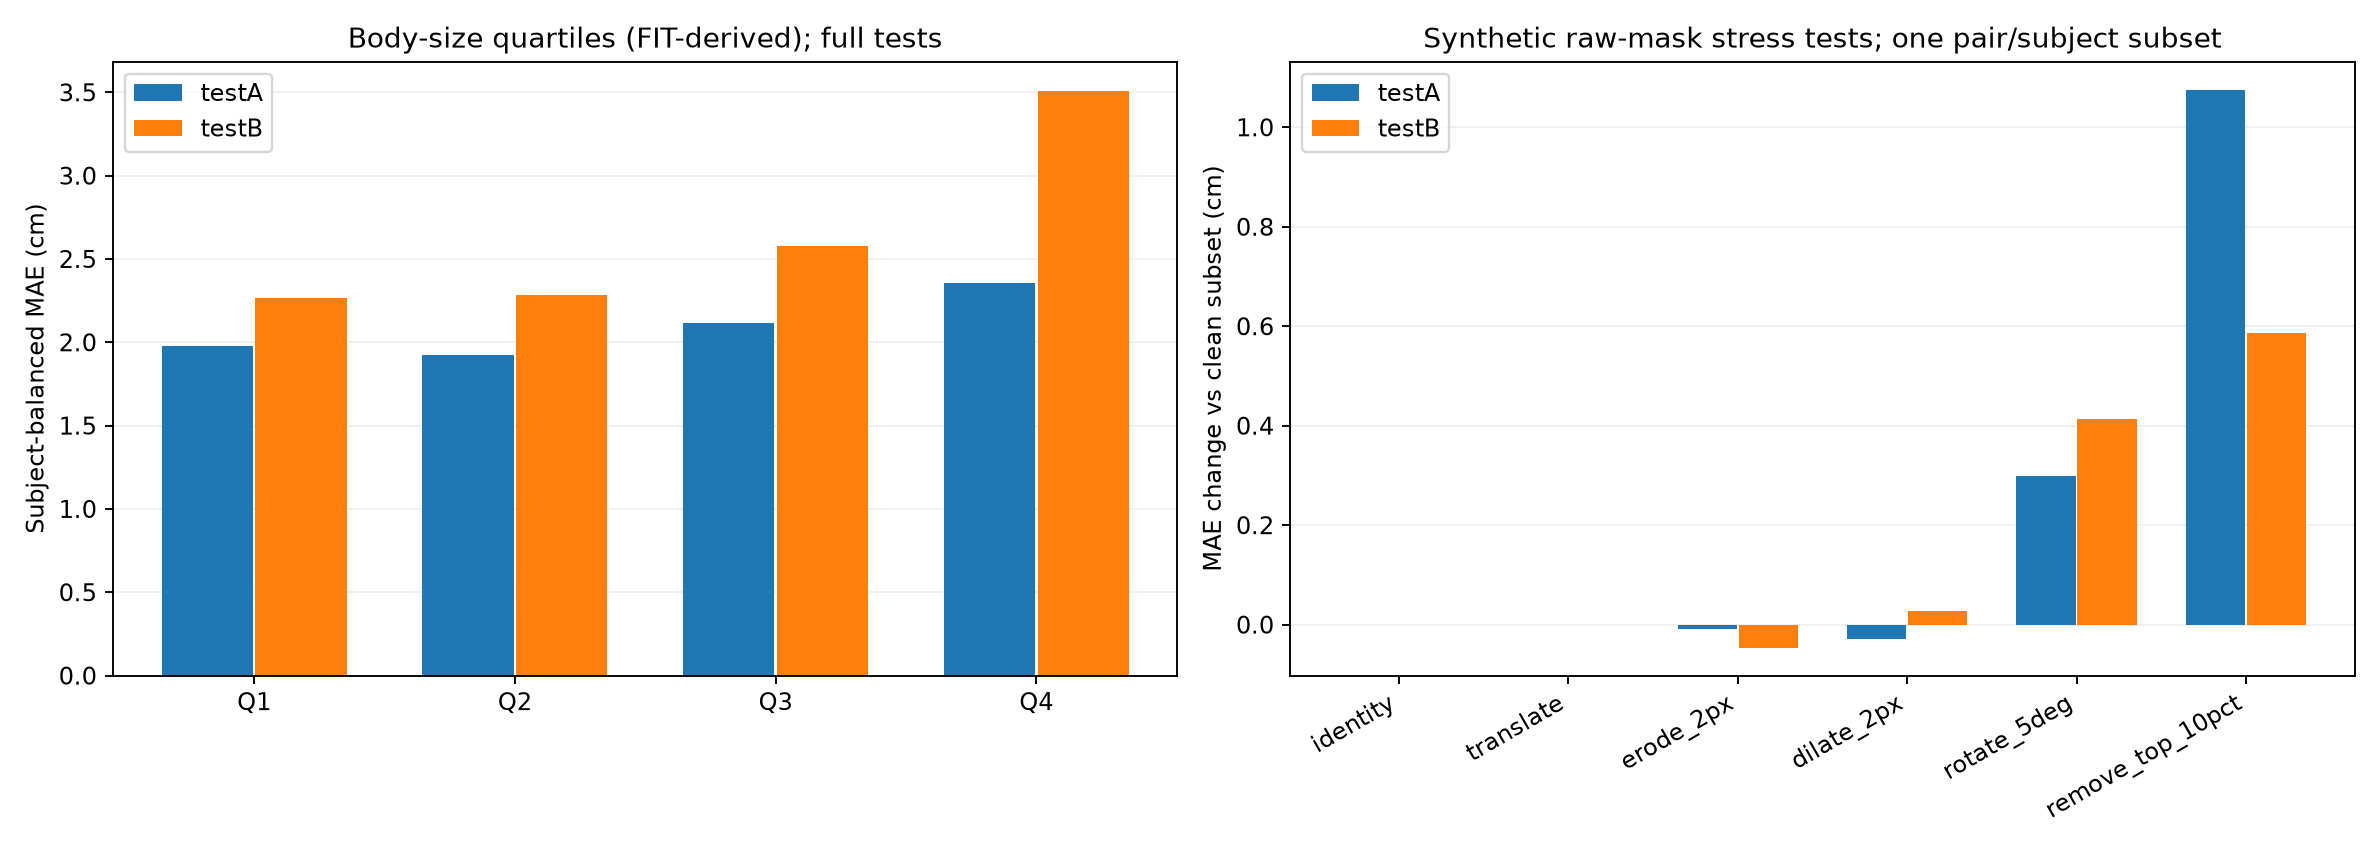

In [3]:
from src.body_vision.analysis import score
for split in ("testA", "testB"):
    with np.load(ROOT / f"data/processed/bodym_phase2/{split}_predictions.npz") as data:
        recalculated = score(data["y"], data["prediction"], data["subject_ids"])
    expected = report["evaluation"][split]["models"]["selected_cnn"]
    assert abs(recalculated["mean_mae_cm"] - expected["mean_mae_cm"]) < 1e-10
    print(split, "independent metric recomputation passed:", recalculated["mean_mae_cm"])
from PIL import Image
display(Image.open(ROOT / "experiments/bodym_phase2/evaluation.png"))

## Error analysis / conclusion

Đọc MAE/RMSE từng chu vi, signed bias và số người mỗi nhóm trong metrics JSON. Nhóm <20 người được đánh dấu, không đủ để kết luận fairness. Nhóm BMI lấy quartiles từ 1.614 người FIT, không fit theo test. Không có tuổi/thiết bị/ánh sáng để kiểm các nhóm đó.

Stress subset có một cặp ảnh/người nên MAE clean subset có thể khác full test. Delta chỉ so trên đúng người còn suy luận được; số rejected và coverage được giữ. Translation phải bất biến; các biến dạng còn lại minh họa lỗi, không được dùng để tune model sau khi nhìn test.

Phase 2 hoàn thành nghiên cứu silhouette trong phạm vi BodyM. RGB pose/segmentation, ảnh điện thoại được đồng ý, uncertainty/OOD/calibration và triển khai ứng dụng chưa đạt evaluation gate. Không suy luận thành phần mỡ/cơ/InBody từ silhouette.